# Defaults and hyperparameter tuning

Start with `SGTClassifier()` or `SGTRegressor()`. Their shared defaults already
use the regularized settings from the [default-selection study](../tuning.rst).
Ordinary fits run ShapeCART with **TAO and bivariate branching off**.

This notebook demonstrates the Optuna `suggest_params` helper on small synthetic
classification and regression datasets. It runs eight trials per task with
three-fold cross-validation. That small budget demonstrates the workflow; it
does not establish optimal settings or guarantee improvement over defaults.
No dataset downloads are needed.

Install `sgtlearn[tune]` in your notebook environment before running the cells:

```console
pip install 'sgtlearn[tune]'
```

Use a Jupyter environment with the current branch installed when trying this
before release. The notebook uses only the tuning extra and the package's normal
dependencies; Optuna is not needed for ordinary estimator fitting.

In [1]:
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import optuna
from sklearn.datasets import make_classification, make_friedman1
from sklearn.metrics import balanced_accuracy_score, mean_squared_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split

from sgtlearn import RandomSGForestClassifier, SGTClassifier, SGTRegressor
from sgtlearn.tune import suggest_params

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
N_TRIALS = 8

/Users/upadhyan/.codex/worktrees/29-tuning-defaults/sgtlearn/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Defaults need no helper

The same tree defaults apply to classifiers, regressors, and forest base trees.
The outer depth is 4; shape functions have unlimited inner depth but at most 4
leaves. Outer/inner minimum leaf sizes are 4/13 and impurity penalties are
1.0/0.01. A regularized default can be too restrictive for very small datasets.
The tuning guide lists every shared setting.

`get_params()` below shows the defaults for the installed version. It is also a
quick way to check that you are running the version containing the new defaults.

In [2]:
default_classifier = SGTClassifier()
default_regressor = SGTRegressor()
shared_names = [
    "max_depth", "num_partitions", "inner_max_depth", "inner_max_leaf_nodes",
    "min_samples_leaf", "inner_min_samples_leaf", "min_impurity_decrease",
    "inner_min_impurity_decrease", "pairwise_candidates", "tao_n_runs",
]
pprint({name: default_classifier.get_params()[name] for name in shared_names})

{'inner_max_depth': None,
 'inner_max_leaf_nodes': 4,
 'inner_min_impurity_decrease': 0.01,
 'inner_min_samples_leaf': 13,
 'max_depth': 4,
 'min_impurity_decrease': 1.0,
 'min_samples_leaf': 4,
 'num_partitions': 7,
 'pairwise_candidates': 0,
 'tao_n_runs': 0}


## Choose which features to tune with

Both keyword arguments belong to **`suggest_params`**, not the estimators:

| Switch | Default | When enabled |
|---|---|---|
| `use_tao` | `False` | One TAO sweep, lambda `1e-4`, pair multiplier `2.0`; these controls stay fixed. |
| `use_bivariate` | `False` | Search positive pair budgets `[0.25, 0.5, 1, 2]` and pair penalties. |

Enable either independently. With bivariate branching off, the helper returns
`pairwise_candidates=0` and does not ask Optuna for pair parameters. For direct
estimator use, `pairwise_candidates=0.5` is the study-recommended opt-in starting
budget; the tuning helper searches a range instead.

This example enables both to demonstrate the optional paths. Set either switch
to `False` and rerun all subsequent cells to try another setup. Keep the flags
fixed within a study, and use the same flags when reconstructing its winner.
The original study's held-out results used both enabled; they do not measure the
final TAO-off, univariate default preset.

In [3]:
tuning_options = {"use_tao": True, "use_bivariate": True}
pprint(tuning_options)

{'use_bivariate': True, 'use_tao': True}


## Split first; keep test data out of Optuna

Each task gets a separate study and an untouched 25% test set. Cross-validation
uses training data only. Any preprocessing you add should be fitted inside each
fold, for example with a scikit-learn pipeline.

The regressor standardizes targets internally using each fit's training data
(and sample weights when supplied). Pass targets in their original units;
predictions and exported leaf values remain in those units. Here the synthetic
targets are deliberately shifted and rescaled.

In [4]:
X_class, y_class = make_classification(
    n_samples=600, n_features=6, n_informative=4, n_redundant=0,
    weights=[0.65, 0.35], class_sep=1.2, random_state=SEED,
)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class, y_class, test_size=0.25, stratify=y_class, random_state=SEED,
)
classification_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

X_reg, y_reg = make_friedman1(n_samples=600, n_features=6, noise=1.0, random_state=SEED)
y_reg = 5000 + 100 * y_reg
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=SEED,
)
regression_cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
print(f"Each task: {len(yc_train)} training rows, {len(yc_test)} reserved test rows")

Each task: 450 training rows, 150 reserved test rows


## Classification: maximize mean balanced accuracy

The helper only suggests keyword arguments. You own the objective, folds,
sampler, and trial budget. All trials use the same folds. `n_jobs=1` keeps this
small example from starting parallel fitting workers.

In [5]:
default_classification_cv = cross_val_score(
    default_classifier, Xc_train, yc_train, cv=classification_cv,
    scoring="balanced_accuracy", n_jobs=1,
).mean()


def classification_objective(trial):
    params = suggest_params(trial, **tuning_options)
    model = SGTClassifier(**params, random_state=SEED)
    return cross_val_score(
        model, Xc_train, yc_train, cv=classification_cv,
        scoring="balanced_accuracy", n_jobs=1,
    ).mean()


classification_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
)
classification_study.optimize(classification_objective, n_trials=N_TRIALS)
print(f"Plain defaults, mean CV balanced accuracy: {default_classification_cv:.4f}")
print(f"Best trial, mean CV balanced accuracy:     {classification_study.best_value:.4f}")

Plain defaults, mean CV balanced accuracy: 0.8186
Best trial, mean CV balanced accuracy:     0.8476


## Regression: minimize mean MSE

Scikit-learn's `neg_mean_squared_error` returns a negative loss so that higher
scores are better. Negate it once to obtain positive MSE and tell Optuna to
**minimize**. The reported MSE is in squared original target units.

These are independent single-task examples. Reproducing the repository's
classification/regression Pareto study requires its benchmark scripts and
dataset panel, not this notebook.

In [6]:
default_regression_mse = -cross_val_score(
    default_regressor, Xr_train, yr_train, cv=regression_cv,
    scoring="neg_mean_squared_error", n_jobs=1,
).mean()


def regression_objective(trial):
    params = suggest_params(trial, **tuning_options)
    model = SGTRegressor(**params, random_state=SEED)
    return -cross_val_score(
        model, Xr_train, yr_train, cv=regression_cv,
        scoring="neg_mean_squared_error", n_jobs=1,
    ).mean()


regression_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
)
regression_study.optimize(regression_objective, n_trials=N_TRIALS)
print(f"Plain defaults, mean CV MSE: {default_regression_mse:,.2f}")
print(f"Best trial, mean CV MSE:     {regression_study.best_value:,.2f}")

Plain defaults, mean CV MSE: 119,970.18
Best trial, mean CV MSE:     105,960.57


## Reconstruct the complete parameter dictionaries

`study.best_params` contains only values sampled by Optuna. It omits fixed
settings such as `inner_max_depth=None` and the TAO controls. Reconstruct with
`FixedTrial` and **the same switches** to get the complete dictionary. You can
then save that dictionary with your model and experiment metadata.

In [7]:
classification_params = suggest_params(
    optuna.trial.FixedTrial(classification_study.best_trial.params), **tuning_options,
)
regression_params = suggest_params(
    optuna.trial.FixedTrial(regression_study.best_trial.params), **tuning_options,
)
print("Classification parameters:")
pprint(classification_params)
print("Regression parameters:")
pprint(regression_params)

Classification parameters:
{'branching_penalty': 0.0,
 'coordinate_descent_max_iters': 5,
 'coordinate_descent_patience': 5,
 'inner_max_depth': None,
 'inner_max_leaf_nodes': 7,
 'inner_min_impurity_decrease': 0.1,
 'inner_min_samples_leaf': 1,
 'max_depth': 9,
 'min_impurity_decrease': 0.1,
 'min_samples_leaf': 7,
 'num_partitions': 4,
 'pairwise_candidates': 0.5,
 'pairwise_penalty': 0.1,
 'tao_lambda': 0.0001,
 'tao_n_runs': 1,
 'tao_pair_scale': 2.0}
Regression parameters:
{'branching_penalty': 0.1,
 'coordinate_descent_max_iters': 5,
 'coordinate_descent_patience': 5,
 'inner_max_depth': None,
 'inner_max_leaf_nodes': 2,
 'inner_min_impurity_decrease': 0.0,
 'inner_min_samples_leaf': 1,
 'max_depth': 10,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'num_partitions': 4,
 'pairwise_candidates': 1.0,
 'pairwise_penalty': 1.0,
 'tao_lambda': 0.0001,
 'tao_n_runs': 1,
 'tao_pair_scale': 2.0}


## Refit on all training data, then evaluate the reserved tests

Only now do we score the test sets. This compares plain defaults (both optional
features off) with the selected configuration under `tuning_options`. Any
difference can reflect both tuning and feature opt-ins; it does not isolate
TAO's or bivariate branching's effect. Eight trials and one synthetic split are
not evidence of general superiority. In the saved run, regression has better CV
MSE but slightly worse test MSE: a validation improvement need not carry over.
Do not keep adjusting the search based on these test scores.

In [8]:
classifier = SGTClassifier(**classification_params, random_state=SEED).fit(Xc_train, yc_train)
regressor = SGTRegressor(**regression_params, random_state=SEED).fit(Xr_train, yr_train)
default_classifier.fit(Xc_train, yc_train)
default_regressor.fit(Xr_train, yr_train)

class_prediction = classifier.predict(Xc_test)
reg_prediction = regressor.predict(Xr_test)
assert class_prediction.shape == yc_test.shape
assert reg_prediction.shape == yr_test.shape
assert np.isfinite(reg_prediction).all()

print("Reserved test balanced accuracy (higher is better)")
print(f"  Plain defaults: {balanced_accuracy_score(yc_test, default_classifier.predict(Xc_test)):.4f}")
print(f"  Selected trial: {balanced_accuracy_score(yc_test, class_prediction):.4f}")
print("Reserved test MSE (lower is better, squared original target units)")
print(f"  Plain defaults: {mean_squared_error(yr_test, default_regressor.predict(Xr_test)):,.2f}")
print(f"  Selected trial: {mean_squared_error(yr_test, reg_prediction):,.2f}")
print("Regression targets, original units:", yr_test[:5].round(1))
print("Regression predictions, original units:", reg_prediction[:5].round(1))

Reserved test balanced accuracy (higher is better)
  Plain defaults: 0.8501
  Selected trial: 0.8732
Reserved test MSE (lower is better, squared original target units)
  Plain defaults: 113,197.62
  Selected trial: 116,226.69
Regression targets, original units: [6108.4 7368.7 7072.  6998.8 6463. ]
Regression predictions, original units: [5928.8 6603.4 6336.6 7150.  6424.1]


## Inspect the search before spending a larger budget

These curves show validation scores, not test scores. Increase `N_TRIALS` for
your own task after deciding the search protocol. A flat curve in this small
example does not prove that a parameter is unimportant.

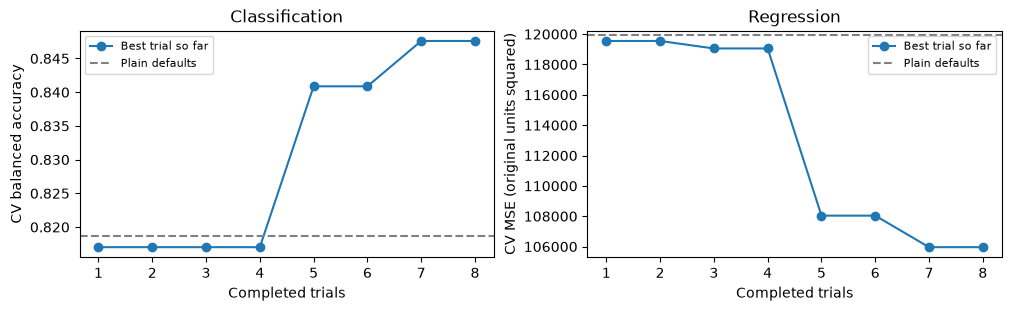

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ax, study, baseline, title, ylabel, maximize in [
    (axes[0], classification_study, default_classification_cv,
     "Classification", "CV balanced accuracy", True),
    (axes[1], regression_study, default_regression_mse,
     "Regression", "CV MSE (original units squared)", False),
]:
    values = np.array([trial.value for trial in study.trials])
    best_so_far = np.maximum.accumulate(values) if maximize else np.minimum.accumulate(values)
    ax.plot(np.arange(1, len(values) + 1), best_so_far, marker="o", label="Best trial so far")
    ax.axhline(baseline, linestyle="--", color="gray", label="Plain defaults")
    ax.set(title=title, xlabel="Completed trials", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

## Reuse tree parameters in a forest

The returned dictionary also works with either forest class. It intentionally
leaves forest-only controls, criterion, and `max_features` to their estimator
defaults (`"sqrt"` for classification, `1.0` for regression). For example:

In [10]:
forest = RandomSGForestClassifier(**classification_params, random_state=SEED)
print("Forest trees:", forest.n_estimators)
print("Forest feature sampling:", forest.max_features)
print("Tree TAO sweeps:", forest.tao_n_runs)
print("Tree pair budget:", forest.pairwise_candidates)

Forest trees: 100
Forest feature sampling: sqrt
Tree TAO sweeps: 1
Tree pair budget: 0.5


This cell constructs a forest; it does not benchmark one. Validate your final
forest separately rather than assuming the best single-tree parameters are
optimal for it.

For real data, first review the [tuning guide](../tuning.rst): useful parameters
include minimum leaf sizes, outer impurity regularization, and inner leaf
count. The ranges come from a finite TabArena study, not universal guarantees.
The helper does not tune `tao_lambda`; you can override the returned dictionary
when your experiment needs a wider search. If you apply `TAO_refine` later,
continue to pass the original-unit regression targets.